In [1]:
import numpy as np
import h2py
import pickle
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy
import pandas
import demes
import demesdraw



mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [13]:
# Load MLE models
mle_models = {}
rates = ["1.1e-8", "1.3e-8", "1.5e-8"]
for rmap in ["bherer", "zhou-JHS"]:
    for rate in rates:
        fnames = []
        lls = []
        for trial in range(30):
            fname = f"fitted_models/main_fit_{rmap}_{rate}_try_{trial}.yaml"
            fnames.append(fname)
            g = demes.load(fname)
            lls.append(g.metadata["opt_info"]["ll"])
        fname = fnames[np.argmax(lls)]
        pvals, pnames = h2py.inference.load_params(fname, "full_model_params.yaml")
        mle_models[(rmap, rate)] = (pvals, pnames)
        print(fname, np.max(lls))

fitted_models/main_fit_bherer_1.1e-8_try_18.yaml -580.7319971174268
fitted_models/main_fit_bherer_1.3e-8_try_22.yaml -579.4650006685165
fitted_models/main_fit_bherer_1.5e-8_try_13.yaml -709.4381430740772
fitted_models/main_fit_zhou-JHS_1.1e-8_try_10.yaml -619.3429292975582
fitted_models/main_fit_zhou-JHS_1.3e-8_try_14.yaml -583.1103379948288
fitted_models/main_fit_zhou-JHS_1.5e-8_try_16.yaml -702.2173004178748


In [15]:
# Load fitted bootstrap parameters
for rmap in ["bherer", "zhou-JHS"]:
    for rate in rates:
        data = []
        for rep in range(500):
            fname = f"fitted_models/boot_fit_{rmap}_{rate}_rep_{rep}.yaml"
            pvals, pnames = h2py.inference.load_params(fname, "full_model_params.yaml")
            data.append(pvals)
        mle = mle_models[(rmap, rate)][0]
        lower_CI = np.quantile(data, 0.025, axis=0) 
        upper_CI = np.quantile(data, 0.975, axis=0) 
        df = pandas.DataFrame({"name": pnames, "MLE": mle, "CI_lower": lower_CI, "CI_upper": upper_CI})
        df.to_csv(f"bootstrap_{rmap}_{rate}.csv")

In [19]:
df = pandas.read_csv("bootstrap_bherer_1.3e-8.csv")
print(df)

    Unnamed: 0     name            MLE      CI_lower       CI_upper
0            0    T_NDH  782697.679085  7.423128e+05  832834.448718
1            1     T_ND  683474.888266  6.090993e+05  732211.089529
2            2    T_AWN  120866.613763  1.176831e+05  133433.856377
3            3     T_CV   59920.938988  5.791709e+04   62118.021886
4            4    T_OOA   57463.823045  5.313159e+04   61065.457487
5            5     T_SL   55103.756451  5.087346e+04   58997.782178
6            6    T_L_S   29211.692913  1.406068e+04   35281.002481
7            7    N_Anc   16700.883020  1.584273e+04   17459.100647
8            8     N_ND    4644.764914  3.290146e+03    7381.164365
9            9    N_Den    3249.669572  3.093468e+03    3653.807344
10          10      N_N    2826.106274  2.580399e+03    3074.773101
11          11   N_Chag     212.051559  1.274976e+02     355.546502
12          12    N_Vin     766.916893  6.182257e+02    1011.669331
13          13    N_Alt     329.544839  1.310078

In [23]:
df = pandas.read_csv("bootstrap_zhou-JHS_1.1e-8.csv")
print(df)

    Unnamed: 0     name            MLE       CI_lower       CI_upper
0            0    T_NDH  862224.538031  792624.795087  903744.812964
1            1     T_ND  782237.131410  670683.554464  796730.085664
2            2    T_AWN  120295.074574  118686.662295  135054.150888
3            3     T_CV   58723.040704   59551.169744   69047.655351
4            4    T_OOA   61345.927031   53156.895140   62269.673263
5            5     T_SL   59403.247566   51341.387271   59755.871879
6            6    T_L_S   31193.968385   10682.553025   35423.341703
7            7    N_Anc   20508.577887   19791.753079   21590.414424
8            8     N_ND    4934.504323    3445.409413    9005.506333
9            9    N_Den    3549.476311    3315.655404    3940.775627
10          10      N_N    3092.630655    2971.347295    3466.209513
11          11   N_Chag     180.934155     191.025976     793.919290
12          12    N_Vin     711.249376     679.626698    1334.458102
13          13    N_Alt     231.89

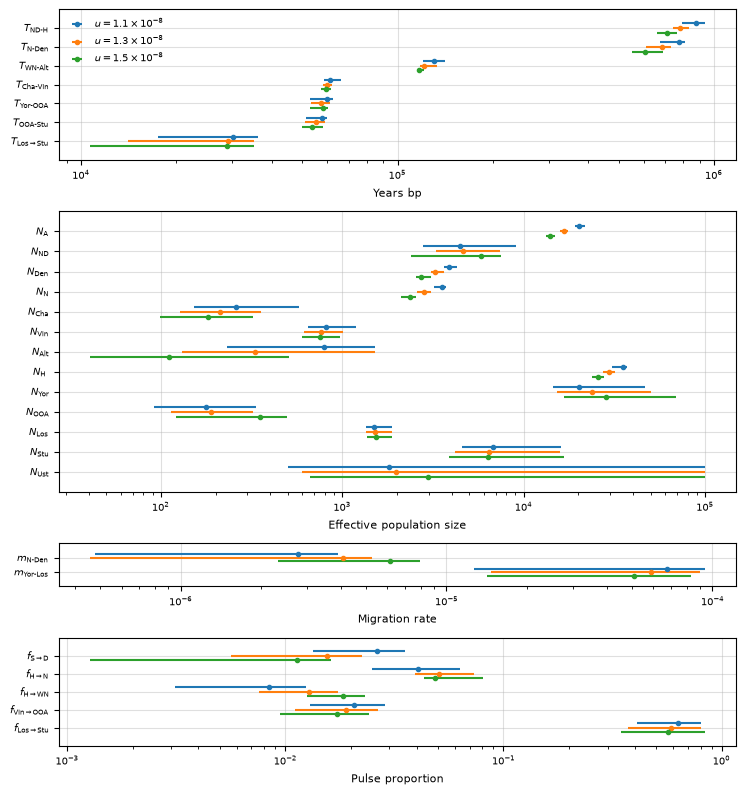

In [3]:
df0 = pandas.read_csv("bootstrap_bherer_1.1e-8.csv")
df1 = pandas.read_csv("bootstrap_bherer_1.3e-8.csv")
df2 = pandas.read_csv("bootstrap_bherer_1.5e-8.csv")
groups = [
    {"params": ['T_NDH', 'T_ND', 'T_AWN', 'T_CV', 'T_OOA', 'T_SL', 'T_L_S'], "log": True},
    {"params": ['N_Anc', 'N_ND', 'N_Den', 'N_N', 'N_Chag', 'N_Vin', 'N_Alt', 'N_MH', 'N_Yor', 'N_OOA', 'N_Los', 'N_Stut', 'N_Ust'],
     "log": True},
    {"params": ["m_ND", "m_LY"], "log": True},
    {"params": ["p_S_D", "p_H_N", "p_H_WN", "p_N_OOA", "p_L_S"], "log": True}
]

x_labels = ["Years bp", "Effective population size", "Migration rate",  "Pulse proportion"]
param_labels = {
    'T_NDH': r'$T_{\text{ND-H}}$',
    'T_ND': r'$T_{\text{N-Den}}$', 
    'T_AWN': r'$T_{\text{WN-Alt}}$', 
    'T_CV': r'$T_{\text{Cha-Vin}}$', 
    'T_OOA': r'$T_{\text{Yor-OOA}}$', 
    'T_SL': r'$T_{\text{OOA-Stu}}$', 
    'T_L_S': r'$T_{\text{Los}\to\text{Stu}}$', 
    'N_Anc': r'$N_{\text{A}}$',
    "N_S": r"$N_{\text{S}}$ (fixed)",
    'N_ND': r'$N_{\text{ND}}$', 
    'N_N': r'$N_{\text{N}}$', 
    'N_MH': r'$N_{\text{H}}$ ', 
    'N_OOA': r'$N_{\text{OOA}}$',
    'N_Alt': r'$N_{\text{Alt}}$', 
    'N_Chag': r'$N_{\text{Cha}}$', 
    'N_Vin': r'$N_{\text{Vin}}$', 
    'N_Den': r'$N_{\text{Den}}$',
    'N_Los': r'$N_{\text{Los}}$',
    'N_Ust': r'$N_{\text{Ust}}$',
    'N_Stut': r'$N_{\text{Stu}}$',
    'N_Yor': r'$N_{\text{Yor}}$', 
    'm_ND': r'$m_{\text{N-Den}}$', 
    'm_LY': r'$m_{\text{Yor-Los}}$', 
    'p_S_D': r'$f_{\text{S} \to \text{D}}$', 
    'p_H_N': r'$f_{\text{H} \to \text{N}}$',
    'p_H_WN': r'$f_{\text{H} \to \text{WN}}$', 
    'p_N_OOA': r'$f_{\text{Vin}\to\text{OOA}}$', 
    'p_L_S': r'$f_{\text{Los}\to\text{Stu}}$',
}

h2py.plotting.plot_param_distributions(
    [df0, df1, df2],
    groups=groups,
    param_labels=param_labels,
    data_labels=["$u =1.1\\times10^{-8}$", "$u =1.3\\times10^{-8}$", "$u =1.5\\times10^{-8}$"],
    figsize=(7.5, 8),
    x_labels=x_labels,
    spread=0.25,
    out="../../figures/u_param_distrs.pdf"
)

In [6]:
df0 = pandas.read_csv("bootstrap_zhou-JHS_1.3e-8.csv")
df1 = pandas.read_csv("bootstrap_bherer_1.3e-8.csv")
groups = [
    {"params": ['T_NDH', 'T_ND', 'T_AWN', 'T_CV', 'T_OOA', 'T_SL', 'T_L_S'], "log": True},
    {"params": ['N_Anc', 'N_ND', 'N_Den', 'N_N', 'N_Chag', 'N_Vin', 'N_Alt', 'N_MH', 'N_Yor', 'N_OOA', 'N_Los', 'N_Stut', 'N_Ust'],
     "log": True},
    {"params": ["m_ND", "m_LY"], "log": True},
    {"params": ["p_S_D", "p_H_N", "p_H_WN", "p_N_OOA", "p_L_S"], "log": True}
]

x_labels = ["Years bp", "Effective population size", "Migration rate",  "Pulse proportion"]

h2py.plotting.plot_param_distributions(
    [df1, df0],
    groups=groups,
    param_labels=param_labels,
    data_labels=["Bhérer", "Zhou JHS"],
    figsize=(9, 10),
    x_labels=x_labels,
    spread=0.18,
    out="map_param_distrs.pdf"
)

NameError: name 'param_labels' is not defined

In [21]:
graph = "fitted_models/main_fit_zhou-JHS_1.3e-8_try_14.yaml"
fname = "../bootstrapped_data/accessible_1e-4M_ccds_flank_zhou-JHS_adj.pkl"
with open(fname, "rb") as fin:
    data = pickle.load(fin)
pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
bins = h2py.parsing._get_bin_tuples(np.logspace(-6, -2, 17))
model = h2py.H2stats.from_demes(graph, u=1.3e-8, r_bins=bins, sampled_demes=pops)
data = h2py.parsing.subset_data(data, to_pops=pops)
stats = []
for i in range(8):
    stats.append(pops[i][:3])
    for j in range(i + 1, 8):
        stats.append(f"{pops[i][:3]}, {pops[j][:3]}")

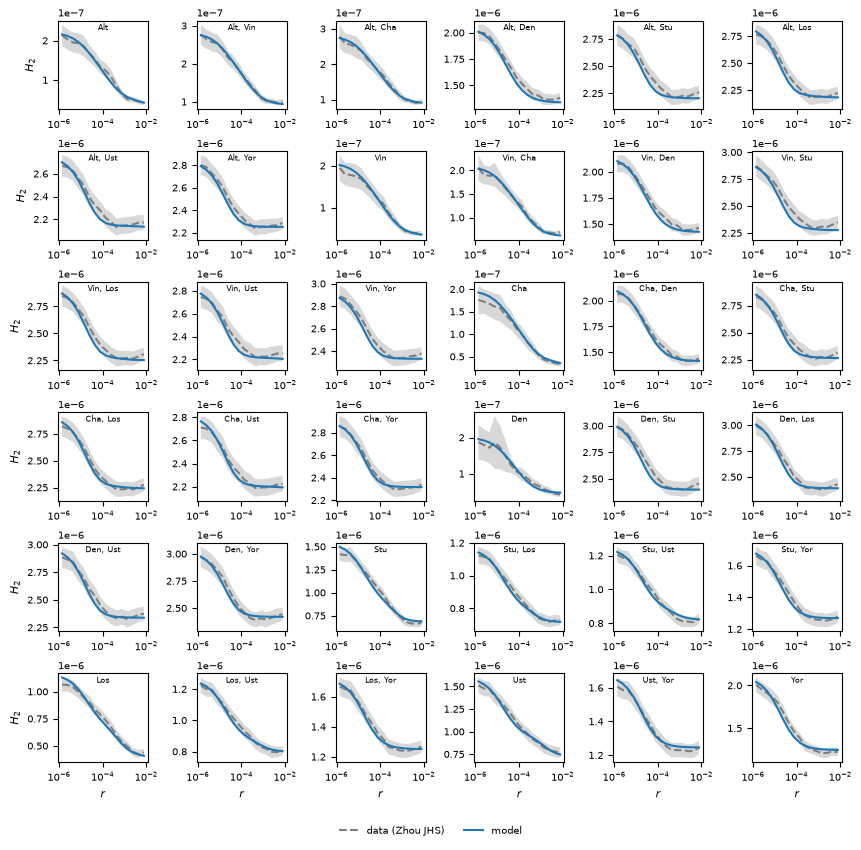

In [22]:
x = h2py.plotting.plot_h2_curves(
    h2_stats=[model],
    means=[data["means"]],
    varcovs=[data["varcovs"]],
    stats=stats,
    fig_size=(8.5, 8.),
    colors=["tab:grey", "tab:blue"],
    pops=pops,
    rows=6, cols=6,
    r_bins=bins, #data["bins"],
    model_labels=["model"],
    data_labels=["data (Zhou JHS)"],
    out_file="../../figures/full_model_zhou_curves.pdf"
)

In [23]:
graph = "fitted_models/main_fit_bherer_1.3e-8_try_14.yaml"
fname = "../bootstrapped_data/accessible_1e-4M_ccds_flank_bherer_adj.pkl"
with open(fname, "rb") as fin:
    data = pickle.load(fin)
pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
bins = h2py.parsing._get_bin_tuples(np.logspace(-6, -2, 17))
model = h2py.H2stats.from_demes(graph, u=1.3e-8, r_bins=bins, sampled_demes=pops)
data = h2py.parsing.subset_data(data, to_pops=pops)
stats = []
for i in range(8):
    stats.append(pops[i][:3])
    for j in range(i + 1, 8):
        stats.append(f"{pops[i][:3]}, {pops[j][:3]}")

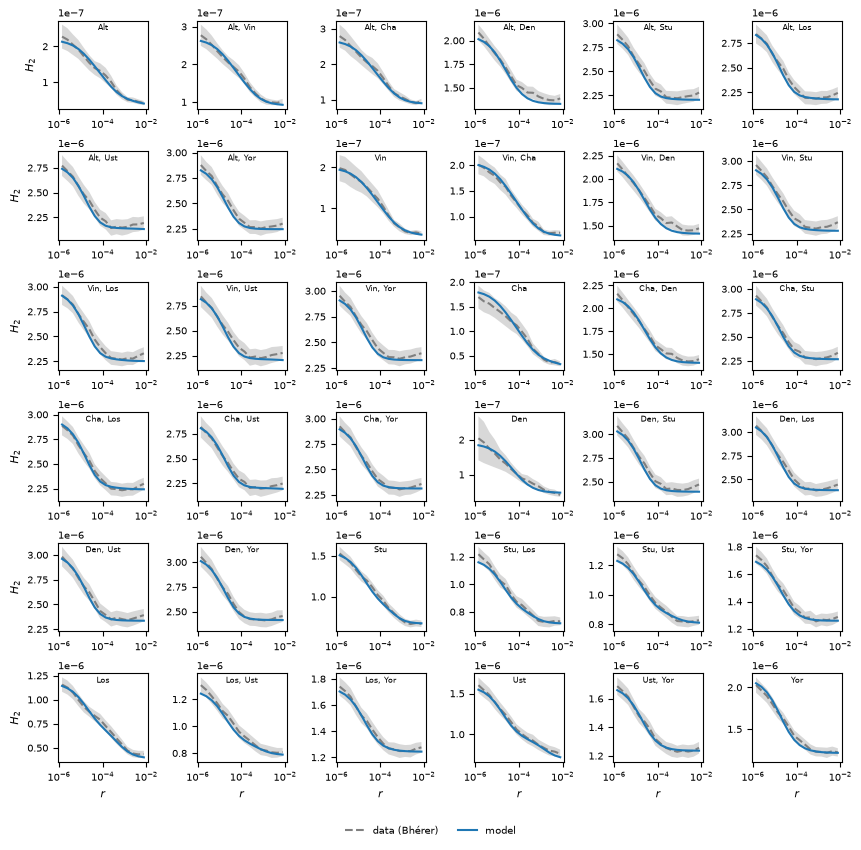

In [24]:
x = h2py.plotting.plot_h2_curves(
    h2_stats=[model],
    means=[data["means"]],
    varcovs=[data["varcovs"]],
    stats=stats,
    fig_size=(8.5, 8),
    colors=["tab:grey", "tab:blue"],
    pops=pops,
    rows=6, cols=6,
    r_bins=bins, #data["bins"],
    model_labels=["model"],
    data_labels=["data (Bhérer)"],
    out_file="../../figures/full_model_bherer_curves.pdf"
)

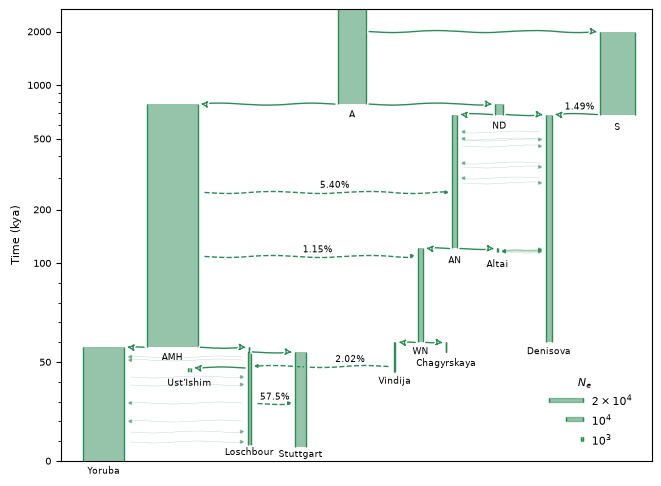

In [30]:
"""
Plot the full model
"""


def plot_focal_model(ax):
    positions = {
        "Chagyrskaya": 1.8e5, 
        "Altai": 2.1e5,
        "Denisova": 2.4e5,
        "Sup": 2.8e5,
        "WN": 1.65e5,
        "N": 1.85e5,
        "ND": 2.11e5,
        "Anc": 1.25e5,
        "Yoruba1": -2e4,
        "Stuttgart": 95000,
        "Loschbour": 65000,
        "UstIshim": 30000,
        "Vindija": 1.5e5,
        "MH": 2e4, 
        "OOA": 50000,
        "BE": 1.1e5
    }

    fname = "fitted_models/main_fit_bherer_1.3e-8_try_22.yaml"
    
    # map deme names to desired labels
    labels = {
        "Yoruba1": "Yoruba", 
        "UstIshim": "Ust'Ishim", 
        "Loschbour": "Loschbour", 
        "Stuttgart": "Stuttgart", 
        "Vindija": "Vindija", 
        "Chagyrskaya": "Chagyrskaya", 
        "Altai": "Altai", 
        "Denisova": "Denisova",
    }
    graph = demes.load(fname)
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        labels=None,
        log_time=False,
        inf_ratio=0.25,
        positions=positions,
        num_lines_per_migration=4,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    # ax.set_xticks([positions[x] for x in labels], [labels[x] for x in labels])
    ax.set_ylabel("Time (kya)")

    label_positions = {
        "Vindija": (positions["Vindija"], 3.9e4),
        "Chagyrskaya": (positions["Chagyrskaya"], 4.8e4),
        "Altai": (positions["Altai"], 9.8e4),
        "Denisova": (positions["Denisova"], 5.4e4),
        "Ust'Ishim":  (positions["UstIshim"], 3.8e4),
        "Loschbour":  (positions["Loschbour"], 3e3),
        "Stuttgart":  (positions["Stuttgart"], 2e3),
        "S": (positions["Sup"], 5.6e5),
        "AN": (positions["N"], 1e5),
        "WN": (positions["WN"], 5.4e4),
        "ND": (positions["ND"], 5.7e5),
        "AMH": (positions["MH"], 5.1e4),
        "A": (positions["Anc"], 6.6e5),
    }
    for label, (x, y) in label_positions.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")

    # annotate pulses
    pulse_annotations = {
        "1.49%": (2.58e5, 7.3e5),
        "5.40%": (1.15e5, 2.65e5),
        "1.15%": (1.05e5, 1.15e5),
        "2.02%": (124000, 5e4),
        "57.5%": ((positions["Stuttgart"] + positions["Loschbour"])/2, 3.1e4)
    }
    for label, (x, y) in pulse_annotations.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")

    ax.set_xticks([positions["Yoruba1"]], ["Yoruba"], fontsize="small")

    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylabel("Time (kya)")
    yticks = [0, 5e4, 1e5, 2e5, 5e5, 1e6, 2e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    yticks = np.concatenate(
        (np.arange(0, 100000, 10000), np.arange(200000, 1000000, 100000)))
    ax.set_yticks(yticks, minor=True)
    ax.set_xlim(-4.5e4, 3e5)
    return


def plot_tube(ax, mid, y, width, height):
    vertices = [
        [mid - width / 2, y + height], 
        [mid - width / 2, y], 
        [mid + width / 2, y + height], 
        [mid + width / 2, y]
    ]
    codes = [np.uint8(1), np.uint8(2), np.uint8(1), np.uint8(2)]
    tube = mpl.path.Path(vertices, codes)
    path_patch = mpl.patches.PathPatch(
        tube, capstyle="butt", fill=False, color=graph_color, zorder=1
    )
    ax.add_patch(path_patch)
    ax.fill_betweenx(
        [y + height, y],
        [mid - width / 2, mid - width / 2],
        [mid + width / 2, mid + width / 2],
        facecolor=graph_color,
        edgecolor=graph_color,
        alpha=0.5,
        zorder=1,
    )
    return


def make_size_legend(ax, center):
    plot_tube(ax, center + 9.5e3, 1e4, 1e3, 2e3)
    plot_tube(ax, center + 5e3, 2e4, 1e4, 2e3)
    plot_tube(ax, center, 3e4, 2e4, 2e3)
    ax.text(center + 1.1e4, 3.9e4, "$N_e$", va="center", ha="center")
    ax.text(center + 1.5e4, 1e4, "$10^3$", va="center", ha="left")
    ax.text(center + 1.5e4, 2e4, "$10^4$", va="center", ha="left")
    ax.text(center + 1.5e4, 3e4, r"$2\times 10^4$", va="center", ha="left")
    return


graph_color = "seagreen"
fig, axs = plt.subplot_mosaic("A", figsize=(6.5, 4.75), layout="constrained")
plot_focal_model(axs["A"])
make_size_legend(axs["A"], 2.5e5)
plt.savefig("../../figures/full_model_bherer.pdf")